# CellScope: Breast Tumour Classification — BITS Virtual Lab Notebook

This notebook independently implements five classifiers for the Wisconsin Diagnostic Breast Cancer dataset.

**Target encoding:** `0 = malignant`, `1 = benign`.  
**Split:** stratified 80% training / 20% testing, `random_state=27`.  
Run all cells in order. The notebook saves trained model artifacts, the test CSV and a metrics table for the Streamlit app.


In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
# 1. Import packages
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)

print("Imports completed.")


Imports completed.


In [4]:
# 2. Load the supplied public dataset
data = pd.read_csv("dataset.csv")
print("Dataset dimensions:", data.shape)
display(data.head())
print("Missing values:", int(data.isna().sum().sum()))
print("Class counts (0=malignant, 1=benign):")
display(data["target"].value_counts().sort_index())


Dataset dimensions: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Missing values: 0
Class counts (0=malignant, 1=benign):


target
0    212
1    357
Name: count, dtype: int64

In [5]:
# 3. Separate predictors and outcome; create a reproducible holdout set
X = data.drop(columns=["target"])
y = data["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=27, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Predictor count:", X.shape[1])


Training rows: 455 | Test rows: 114
Predictor count: 30


In [6]:
# 4. Configure the five classifiers
estimators = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, C=0.8, random_state=27))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(max_depth=4, min_samples_leaf=4, random_state=27))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=7, weights="distance"))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB(var_smoothing=1e-8))
    ]),
    "Support Vector Machine": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("classifier", SVC(C=1.5, kernel="rbf", probability=True, random_state=27))
    ])
}
print("Configured classifiers:", list(estimators))


Configured classifiers: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Support Vector Machine']


In [7]:
# 5. Train, evaluate and export each classifier
artifact_names = {
    "Logistic Regression": "logistic_regression",
    "Decision Tree": "decision_tree",
    "K-Nearest Neighbors": "knn",
    "Gaussian Naive Bayes": "gaussian_nb",
    "Support Vector Machine": "svm"
}
Path("model").mkdir(exist_ok=True)
fitted_models = {}
metric_rows = []

for label, estimator in estimators.items():
    estimator.fit(X_train, y_train)
    fitted_models[label] = estimator
    predicted = estimator.predict(X_test)
    probability = estimator.predict_proba(X_test)[:, 1]
    metric_rows.append({
        "Model": label,
        "Accuracy": accuracy_score(y_test, predicted),
        "AUC": roc_auc_score(y_test, probability),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted)
    })
    joblib.dump(estimator, Path("model") / f"{artifact_names[label]}.joblib")

metrics_table = pd.DataFrame(metric_rows)
display(metrics_table.round(4))
metrics_table.to_csv("model_metrics.csv", index=False)
print("Five model files and model_metrics.csv saved.")


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9980,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9474,0.9630,0.9714,0.9444,0.9577,0.8886
2,K-Nearest Neighbors,0.9737,0.9858,0.9726,0.9861,0.9793,0.9433
3,Gaussian Naive Bayes,0.9386,0.9868,0.9114,1.0000,0.9536,0.8715
4,Support Vector Machine,0.9912,0.9980,0.9863,1.0000,0.9931,0.9812


Five model files and model_metrics.csv saved.


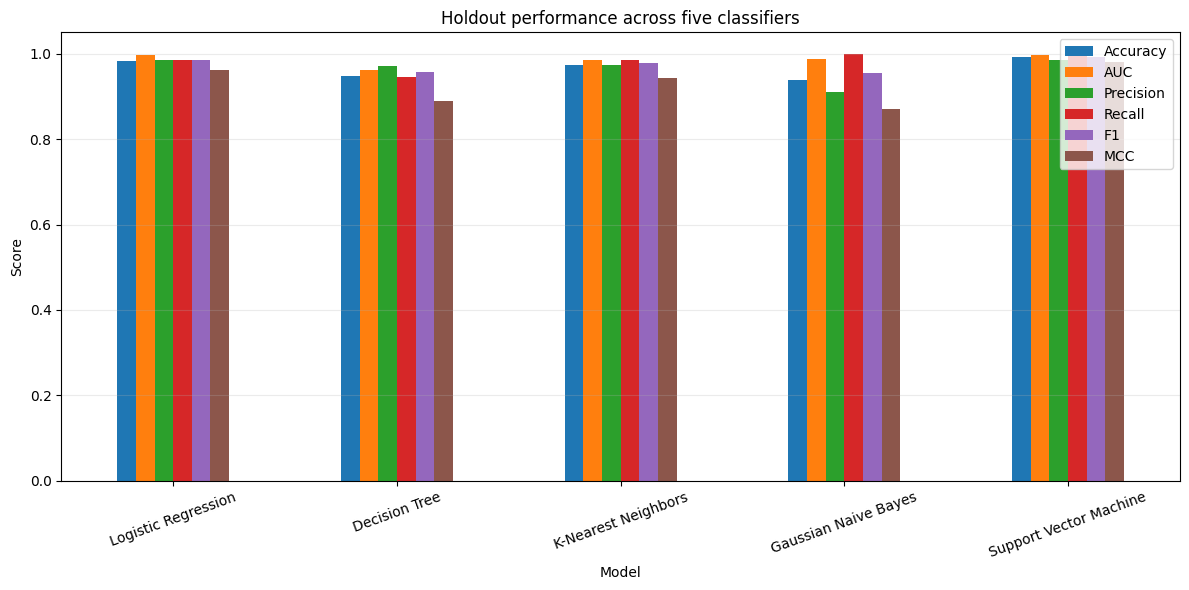

In [8]:
# 6. Visualize the metric comparison
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = metrics_table.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05), rot=20
)
ax.set_title("Holdout performance across five classifiers")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


\n==============================================================
Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



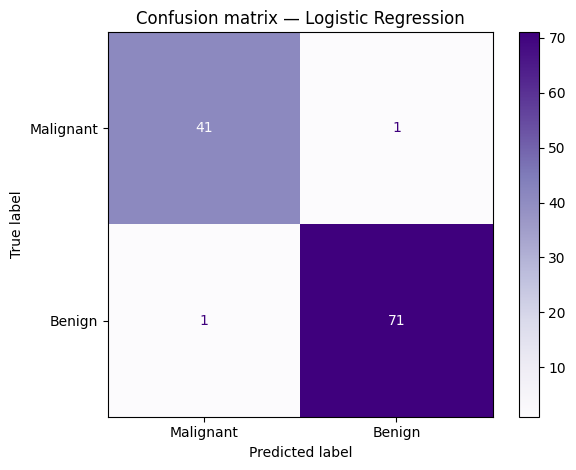

\n==============================================================
Decision Tree
              precision    recall  f1-score   support

   Malignant       0.91      0.95      0.93        42
      Benign       0.97      0.94      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



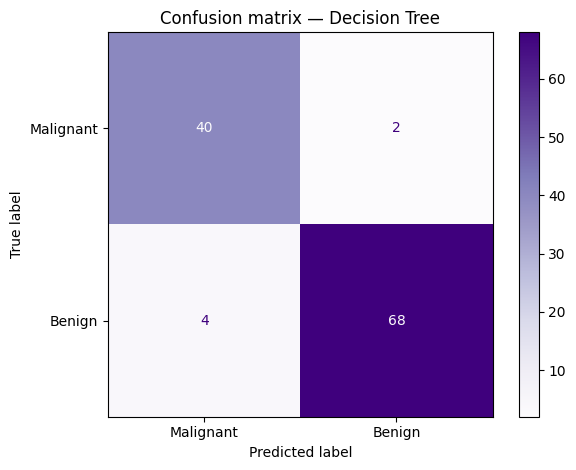

\n==============================================================
K-Nearest Neighbors
              precision    recall  f1-score   support

   Malignant       0.98      0.95      0.96        42
      Benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



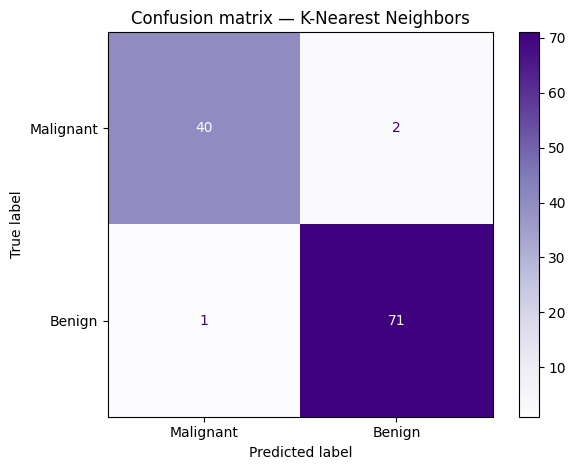

\n==============================================================
Gaussian Naive Bayes
              precision    recall  f1-score   support

   Malignant       1.00      0.83      0.91        42
      Benign       0.91      1.00      0.95        72

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



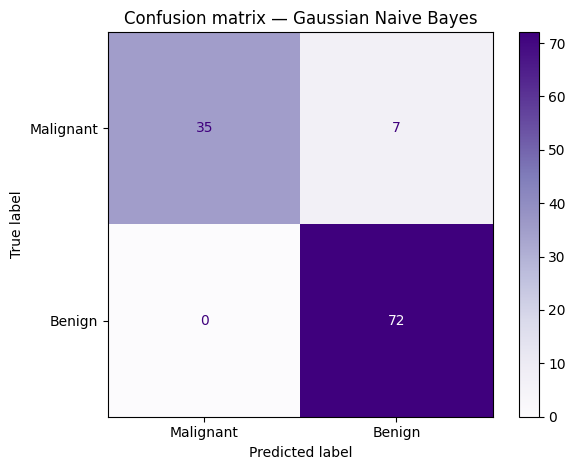

\n==============================================================
Support Vector Machine
              precision    recall  f1-score   support

   Malignant       1.00      0.98      0.99        42
      Benign       0.99      1.00      0.99        72

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



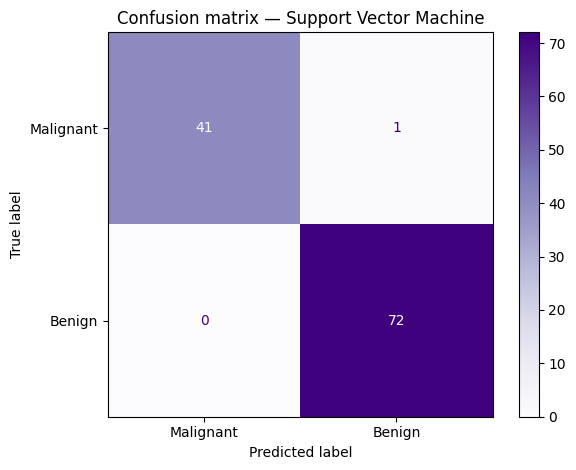

In [9]:
# 7. Confusion matrices and classification reports
for label, estimator in fitted_models.items():
    predicted = estimator.predict(X_test)
    print("\\n" + "=" * 62)
    print(label)
    print(classification_report(
        y_test, predicted,
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted,
        display_labels=["Malignant", "Benign"],
        cmap="Purples"
    )
    plt.title(f"Confusion matrix — {label}")
    plt.tight_layout()
    plt.show()


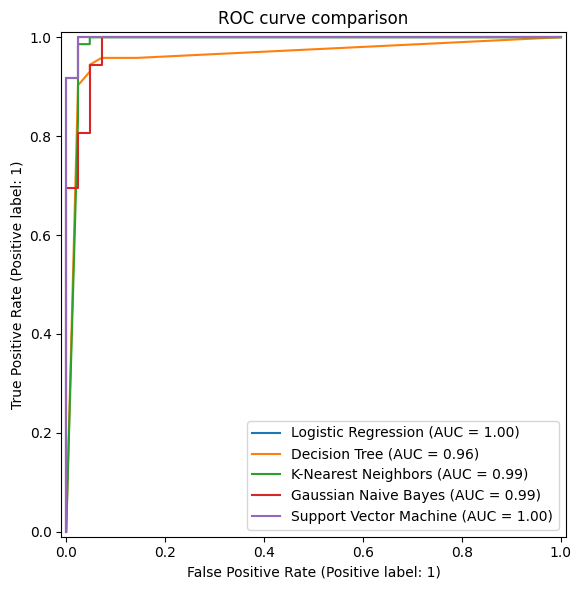

In [10]:
# 8. ROC curves for all models
fig, ax = plt.subplots(figsize=(8, 6))
for label, estimator in fitted_models.items():
    RocCurveDisplay.from_estimator(estimator, X_test, y_test, name=label, ax=ax)
ax.set_title("ROC curve comparison")
plt.tight_layout()
plt.show()


In [11]:
# 9. Export the held-out test data for Streamlit
test_export = X_test.copy()
test_export["target"] = y_test.values
test_export.to_csv("test_data.csv", index=False)

print("Exported test_data.csv with", len(test_export), "rows.")
print("Exported files:", sorted(p.name for p in Path("model").glob("*.joblib")))


Exported test_data.csv with 114 rows.
Exported files: ['decision_tree.joblib', 'gaussian_nb.joblib', 'knn.joblib', 'logistic_regression.joblib', 'svm.joblib']


## Interpretation prompts

Write your own observations after examining the metric table and plots:

- Which model has the highest AUC?
- Which model has the highest recall for the positive class (benign)?
- Does the Decision Tree perform differently from the scaled models?
- Which model gives the most balanced performance according to F1 and MCC?
- Explain why the best model on this particular test split should not automatically be treated as best for clinical use.

Do not treat these models as medical diagnostic tools.
